<a href="https://colab.research.google.com/github/Ayan-Rajput-Analysis/Ayan-Rajput-Analysis/blob/main/EDA_ANALYSIS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="darkgrid", palette="Set2")
PALETTE = sns.color_palette("Set2")

### ** STEP 1 — Load**

In [ ]:
df = pd.read_csv("/content/drive/MyDrive/EDA_Analysis/NetFlix.csv")

# STEP 2 — Top 5 **Rows**

In [ ]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,genres,...,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23
0,s1,TV Show,0.03,NaN,Brazil,14-Aug-20,2020,TV-MA,4,"International TV Shows, TV Dramas, TV Sci-Fi &...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,s10,Movie,1920,Vikram Bhatt,India,15-Dec-17,2008,TV-MA,143,"Horror Movies, International Movies, Thrillers",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,s100,Movie,3 Heroines,Iman Brotoseno,Indonesia,5-Jan-19,2016,TV-PG,124,"Dramas, International Movies, Sports Movies",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,s1000,Movie,Blue Mountain State: The Rise of Thadland,Lev L. Spiro,United States,1-Mar-16,2016,R,90,Comedies,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,s1001,TV Show,Blue Planet II,NaN,United Kingdom,3-Dec-18,2017,TV-G,1,"British TV Shows, Docuseries, Science & Nature TV",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# STEP 3 — **Shape**

In [ ]:
df.shape

(7787, 24)

# STEP 4 — Data **Types**

In [ ]:
df.dtypes

,0
show_id,object
type,object
title,object
director,object
country,object
date_added,object
release_year,int64
rating,object
duration,int64
genres,object


# STEP 5 — Show All **Nulls**

In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,2
director,2389
country,507
date_added,10
release_year,0
rating,7
duration,0
genres,0


# STEP 6 — Null **Percentage**

In [ ]:
df.isnull().sum() / len(df) * 100

,0
show_id,0.000000
type,0.000000
title,0.025684
director,30.679337
country,6.510851
date_added,0.128419
release_year,0.000000
rating,0.089893
duration,0.000000
genres,0.000000


## STEP 7 — Statistical **Summary**

In [ ]:
df.describe()

,release_year,duration,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23
count,7787.000000,7787.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,2013.932580,69.122769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,8.757395,50.950743,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1925.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,2013.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,2017.000000,88.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2018.000000,106.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,2021.000000,312.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# STEP 8 — Fill Missing **Values**

In [ ]:
df["director"]   = df["director"].fillna("Unknown")
df["country"]    = df["country"].fillna("Unknown")
df["rating"]     = df["rating"].fillna("Unknown")
df["title"]      = df["title"].fillna("Unknown")
df["date_added"] = df["date_added"].fillna("Unknown")

df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
genres,0


# STEP 9 — Drop **Duplicates**

In [ ]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

(7787, 24)

# TEP 10 — Parse **date_added**

In [ ]:
df["date_added"] = pd.to_datetime(df["date_added"], format="%d-%b-%y", errors="coerce")
df["year_added"]  = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

df[["date_added", "year_added", "month_added"]].head()

,date_added,year_added,month_added
0,2020-08-14,2020.0,8.0
1,2017-12-15,2017.0,12.0
2,2019-01-05,2019.0,1.0
3,2016-03-01,2016.0,3.0
4,2018-12-03,2018.0,12.0


# STEP 11 — Value Counts: Content **Type**

In [ ]:
df["type"].value_counts()

,count
type,
Movie,5377
TV Show,2410


# STEP 12 — Value Counts: **Rating**

In [ ]:
df["rating"].value_counts()

,count
rating,
TV-MA,2863
TV-14,1931
TV-PG,806
R,665
PG-13,386
TV-Y,280
TV-Y7,271
PG,247
TV-G,194


# STEP 13 — Release Year **Range**

In [ ]:
print("Min year:", df["release_year"].min())
print("Max year:", df["release_year"].max())

Min year: 1925
Max year: 2021


# STEP 14 — Top 10 **Countries**

In [ ]:
df[df["country"] != "Unknown"]["country"] \
.str.split(",").explode().str.strip() \
.value_counts().head(10)


,count
country,
United States,3297
India,990
United Kingdom,723
Canada,412
France,349
Japan,287
Spain,215
South Korea,212
Germany,199


# STEP 15 — Top 10 **Genres**

In [ ]:
df["genres"] \
.str.split(",").explode().str.strip() \
.value_counts().head(10)

,count
genres,
International Movies,2437
Dramas,2106
Comedies,1471
International TV Shows,1199
Documentaries,786
Action & Adventure,721
TV Dramas,704
Independent Movies,673
Children & Family Movies,532


# STEP 16 — Top 10 **Directors**

In [ ]:
df[df["director"] != "Unknown"]["director"] \
.value_counts().head(10)

,count
director,
"Raúl Campos, Jan Suter",18
Marcus Raboy,16
Jay Karas,14
Cathy Garcia-Molina,13
Martin Scorsese,12
Jay Chapman,12
Youssef Chahine,12
Steven Spielberg,10
David Dhawan,9


# STEP 17 — Plot: Content Type **Distribution**

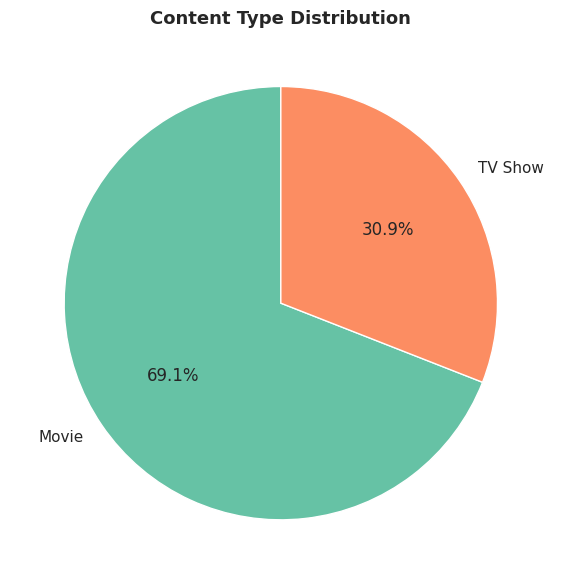

In [ ]:
type_counts = df["type"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%",
        colors=PALETTE[:2], startangle=90,
        wedgeprops=dict(edgecolor="white"))
plt.title("Content Type Distribution", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("17_content_type.png", dpi=150)
plt.show()


# STEP 18 — Plot: Rating **Distribution**

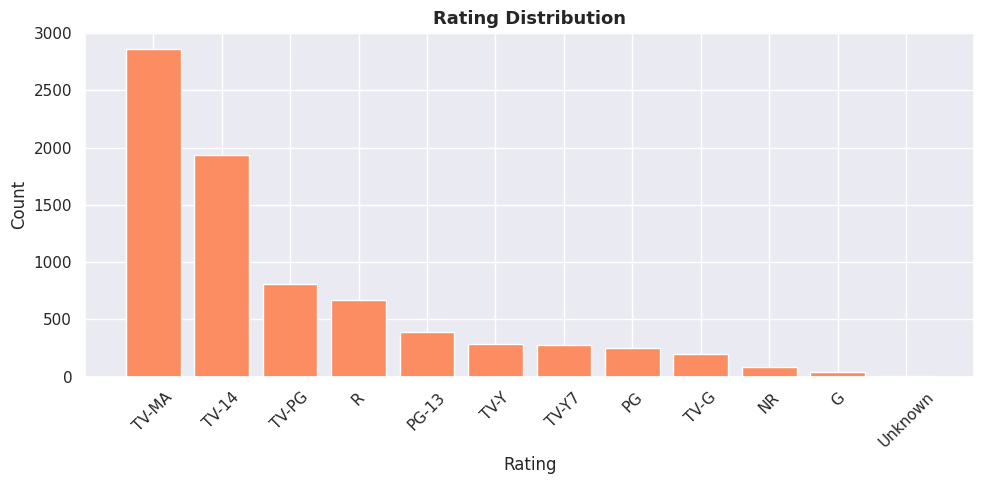

In [ ]:
rating_counts = df["rating"].value_counts().head(12)

plt.figure(figsize=(10, 5))
plt.bar(rating_counts.index, rating_counts.values,
        color=PALETTE[1], edgecolor="white")
plt.title("Rating Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("18_rating.png", dpi=150)
plt.show()


# STEP 19 — Plot: Release Year **Distribution**

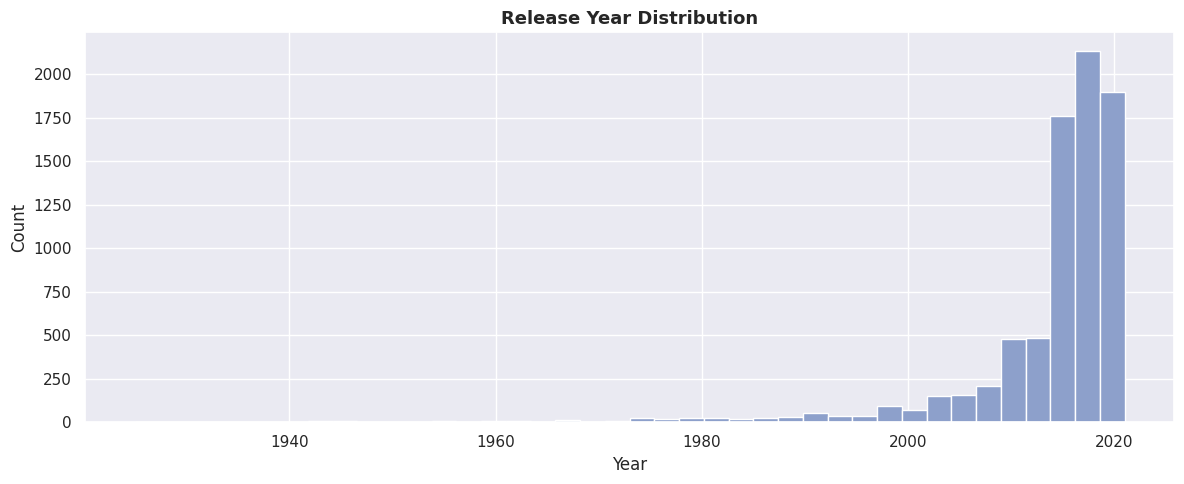

In [ ]:
plt.figure(figsize=(12, 5))
plt.hist(df["release_year"], bins=40, color=PALETTE[2], edgecolor="white")
plt.title("Release Year Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("19_release_year.png", dpi=150)
plt.show()

# STEP 20 — Plot: Duration **Distribution**

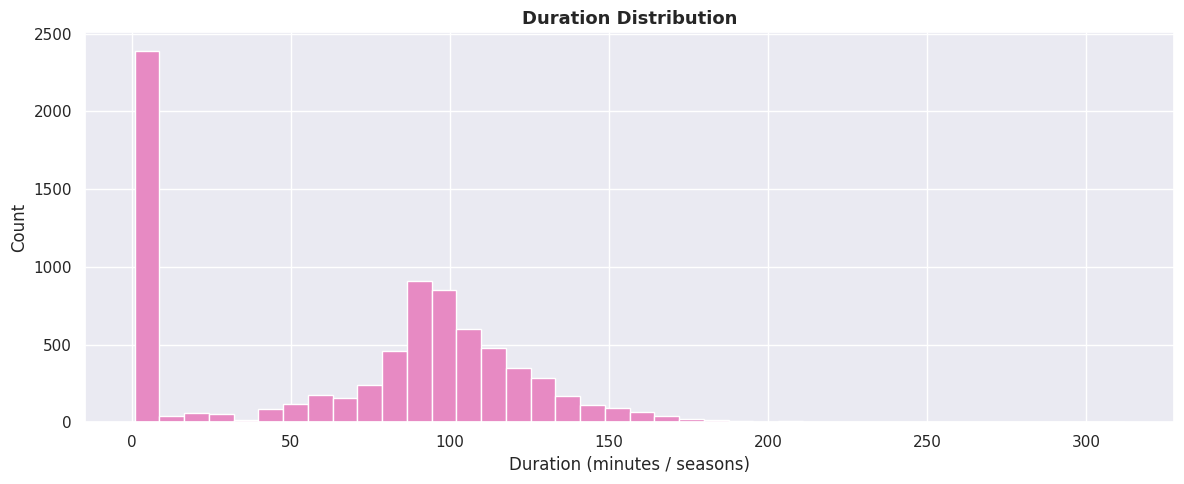

In [ ]:
plt.figure(figsize=(12, 5))
plt.hist(df["duration"], bins=40, color=PALETTE[3], edgecolor="white")
plt.title("Duration Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Duration (minutes / seasons)")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig("20_duration.png", dpi=150)
plt.show()

# STEP 21 — Plot: Top 10 **Countries**

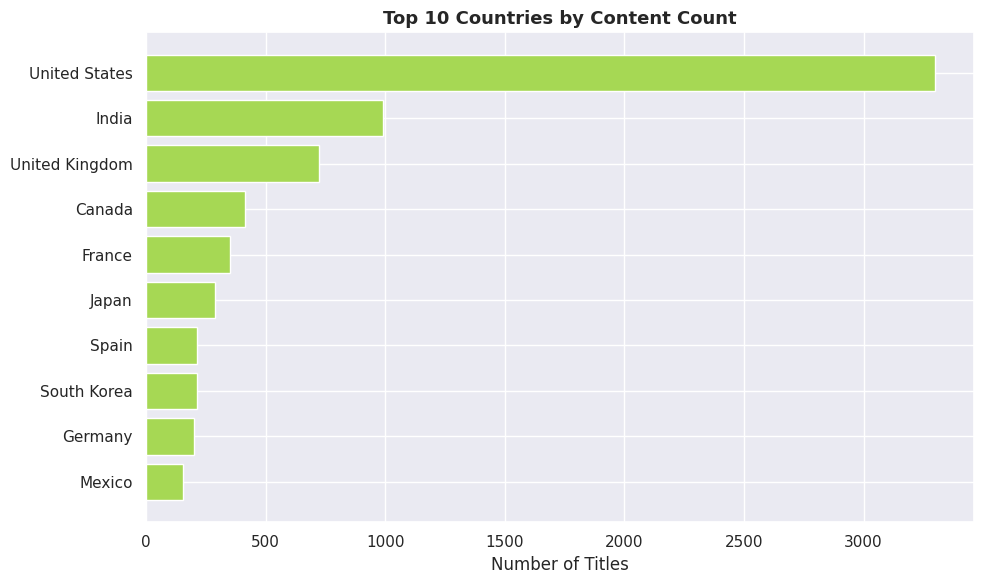

In [ ]:
top_countries = df[df["country"] != "Unknown"]["country"] \
    .str.split(",").explode().str.strip() \
    .value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_countries.index, top_countries.values,
         color=PALETTE[4], edgecolor="white")
plt.title("Top 10 Countries by Content Count", fontsize=13, fontweight="bold")
plt.xlabel("Number of Titles")
plt.tight_layout()
plt.savefig("21_top_countries.png", dpi=150)
plt.show()

# STEP 22 — Plot: Top 10 **Genres**

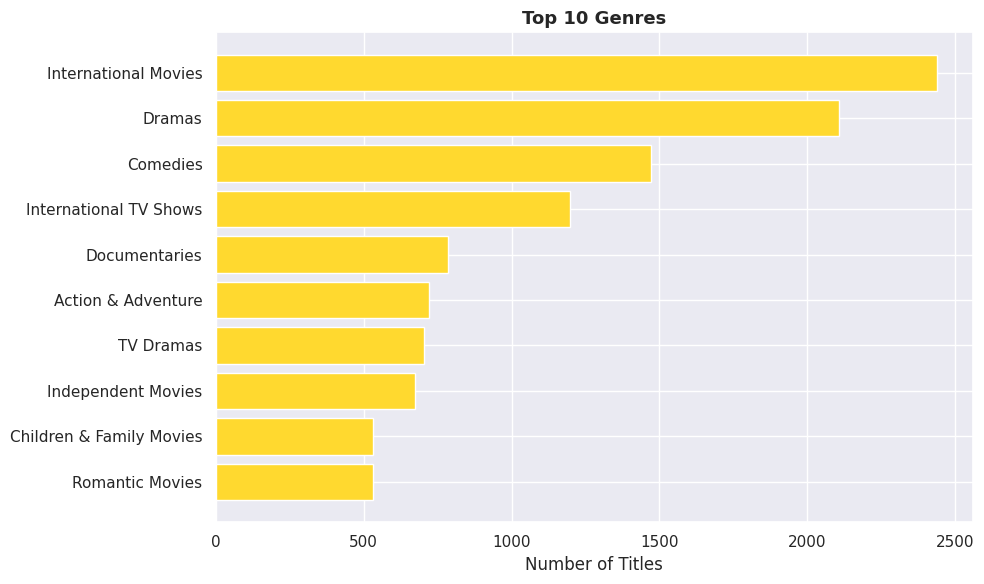

In [ ]:
top_genres = df["genres"] \
    .str.split(",").explode().str.strip() \
    .value_counts().head(10).sort_values()

plt.figure(figsize=(10, 6))
plt.barh(top_genres.index, top_genres.values,
         color=PALETTE[5], edgecolor="white")
plt.title("Top 10 Genres", fontsize=13, fontweight="bold")
plt.xlabel("Number of Titles")
plt.tight_layout()
plt.savefig("22_top_genres.png", dpi=150)
plt.show()

# STEP 23 — Plot: Rating vs Content **Type**

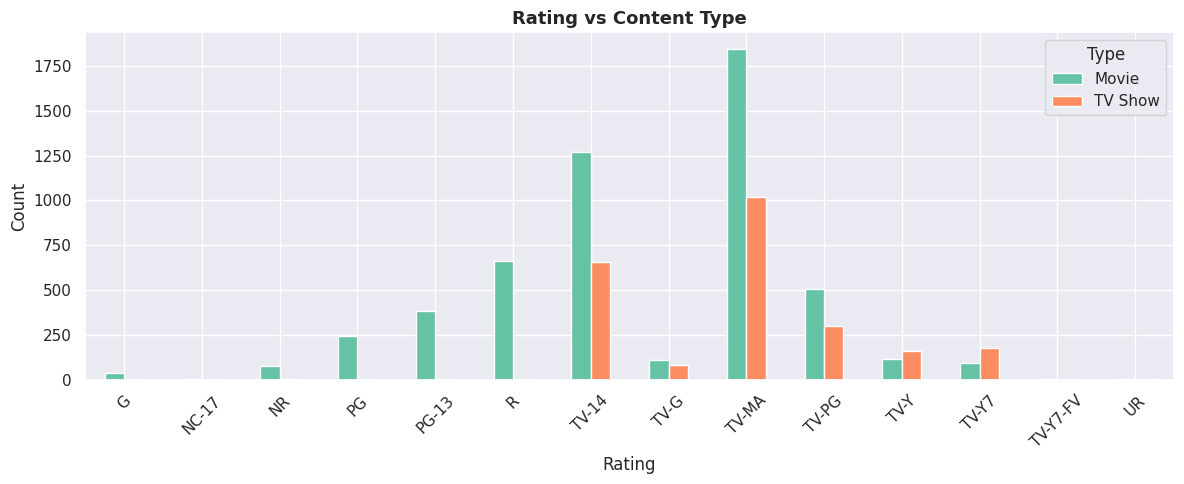

In [ ]:
pivot = df[df["rating"] != "Unknown"] \
    .groupby(["rating", "type"]).size().unstack(fill_value=0)

pivot.plot(kind="bar", figsize=(12, 5), color=PALETTE[:2], edgecolor="white")
plt.title("Rating vs Content Type", fontsize=13, fontweight="bold")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.legend(title="Type")
plt.tight_layout()
plt.savefig("23_rating_vs_type.png", dpi=150)
plt.show()

# STEP 24 — Plot: Yearly Content Trend by **Type**

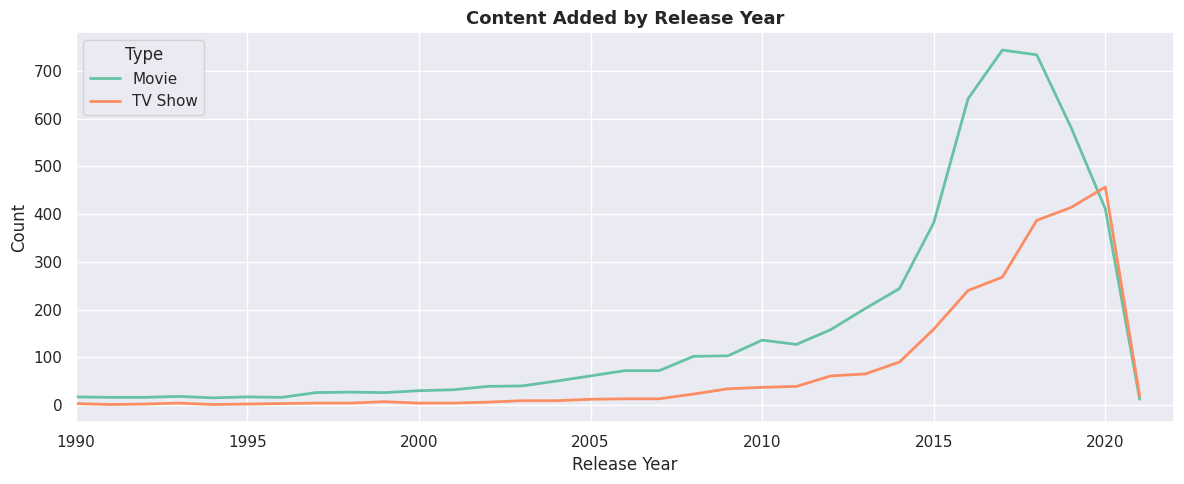

In [ ]:
yearly = df.groupby(["release_year", "type"]).size().reset_index(name="count")

plt.figure(figsize=(12, 5))
for t, grp in yearly.groupby("type"):
    plt.plot(grp["release_year"], grp["count"], label=t, linewidth=2)
plt.title("Content Added by Release Year", fontsize=13, fontweight="bold")
plt.xlabel("Release Year")
plt.ylabel("Count")
plt.xlim(1990, 2022)
plt.legend(title="Type")
plt.tight_layout()
plt.savefig("24_yearly_trend.png", dpi=150)
plt.show()

# STEP 25 — Plot: Monthly Additions Over **Time**

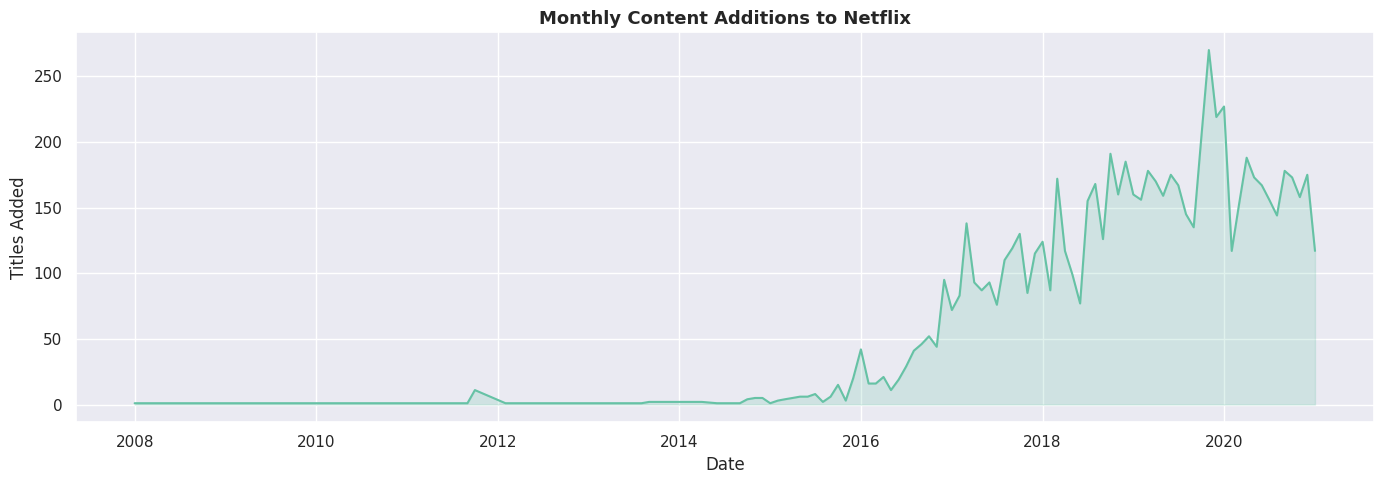

In [ ]:
monthly = df.dropna(subset=["year_added", "month_added"]) \
    .groupby(["year_added", "month_added"]).size().reset_index(name="count")
monthly["date"] = pd.to_datetime(
    monthly[["year_added", "month_added"]]
    .rename(columns={"year_added": "year", "month_added": "month"})
    .assign(day=1)
)
monthly.sort_values("date", inplace=True)

plt.figure(figsize=(14, 5))
plt.plot(monthly["date"], monthly["count"], color=PALETTE[0], linewidth=1.5)
plt.fill_between(monthly["date"], monthly["count"], alpha=0.2, color=PALETTE[0])
plt.title("Monthly Content Additions to Netflix", fontsize=13, fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Titles Added")
plt.tight_layout()
plt.savefig("25_monthly_additions.png", dpi=150)
plt.show()

# STEP 26 — Plot: Year × Month **Heatmap**

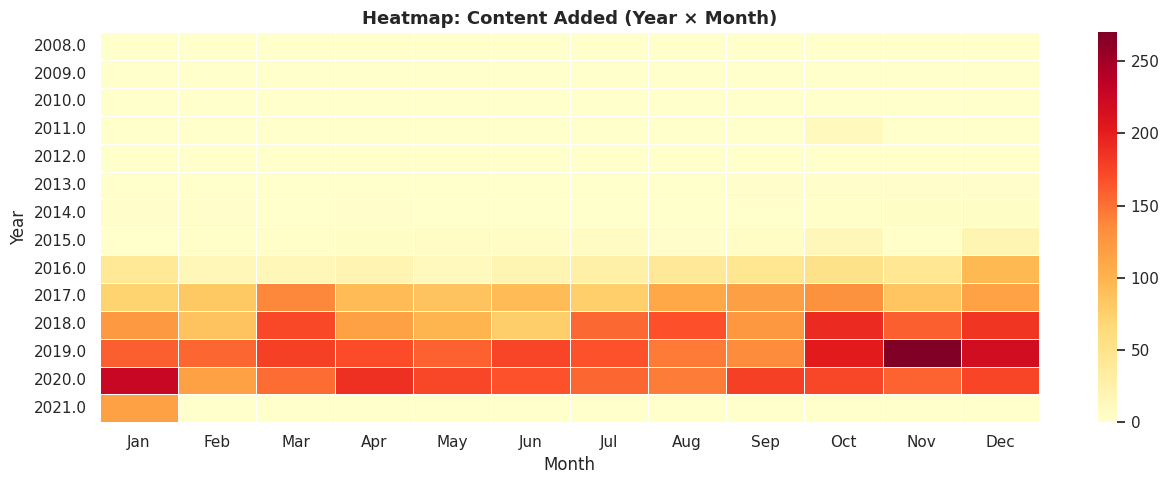

In [ ]:
heat_data = df.dropna(subset=["year_added", "month_added"]) \
    .groupby(["year_added", "month_added"]).size().unstack(fill_value=0)

month_names = ["Jan","Feb","Mar","Apr","May","Jun",
               "Jul","Aug","Sep","Oct","Nov","Dec"]
heat_data.columns = [month_names[int(m)-1] for m in heat_data.columns]

plt.figure(figsize=(13, 5))
sns.heatmap(heat_data, cmap="YlOrRd", linewidths=0.4,
            linecolor="white", annot=False)
plt.title("Heatmap: Content Added (Year × Month)", fontsize=13, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.savefig("26_heatmap.png", dpi=150)
plt.show()


# STEP 27 — Plot: Duration Boxplot by **Type**

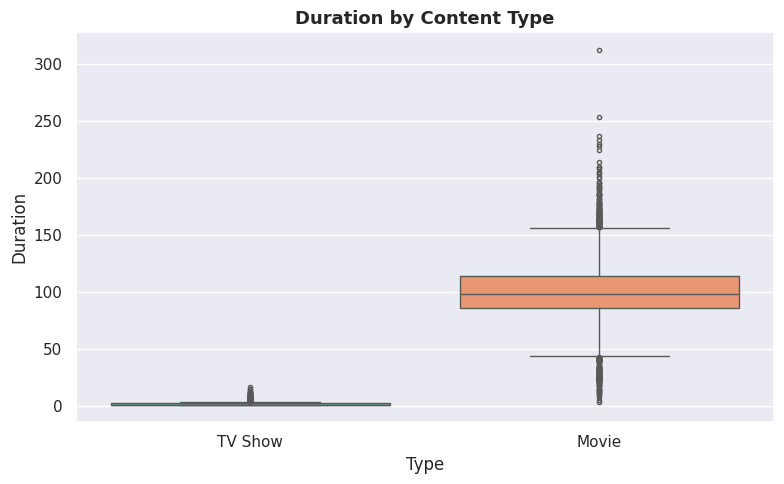

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="type", y="duration", hue="type",
            palette=PALETTE[:2], legend=False,
            flierprops=dict(marker="o", markersize=3))
plt.title("Duration by Content Type", fontsize=13, fontweight="bold")
plt.xlabel("Type")
plt.ylabel("Duration")
plt.tight_layout()
plt.savefig("27_duration_boxplot.png", dpi=150)
plt.show()

# STEP 28 — Correlation **Heatmap**

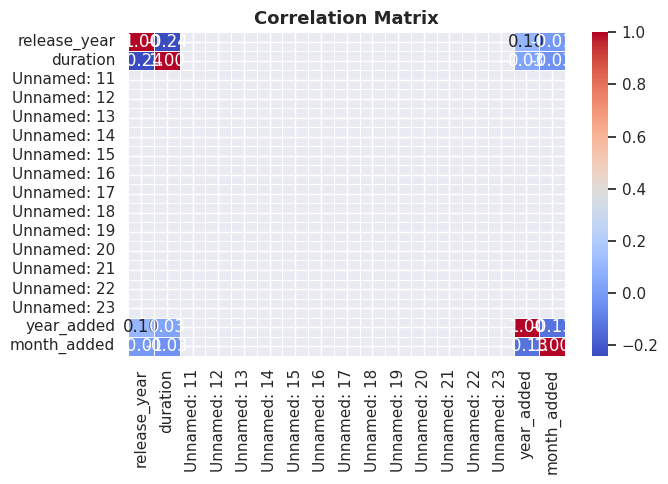

In [ ]:
num_df = df.select_dtypes(include="number")
corr   = num_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            linewidths=0.5, linecolor="white")
plt.title("Correlation Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("28_correlation.png", dpi=150)
plt.show()

# STEP 29 — Outlier Detection (IQR)**bold text**

duration: 1 outliers — range [-154.0, 262.0]
release_year: 745 outliers — range [2005.5, 2025.5]


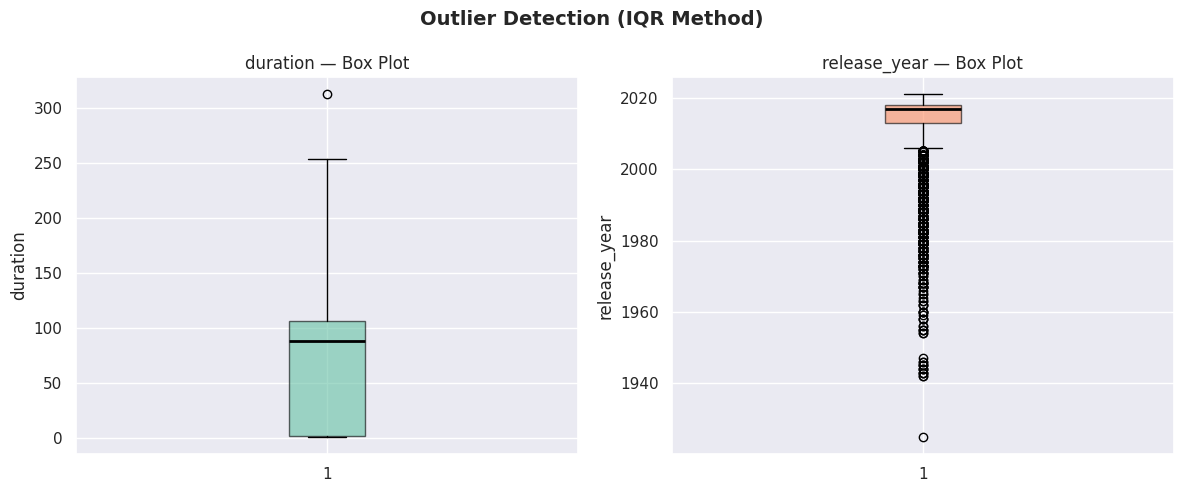

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Outlier Detection (IQR Method)", fontsize=14, fontweight="bold")

for ax, col, color in zip(axes, ["duration", "release_year"], PALETTE[:2]):
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print(f"{col}: {len(outliers)} outliers — range [{lower:.1f}, {upper:.1f}]")

    ax.boxplot(df[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.6),
               medianprops=dict(color="black", linewidth=2))
    ax.set_title(f"{col} — Box Plot")
    ax.set_ylabel(col)

plt.tight_layout()
plt.savefig("29_outliers.png", dpi=150)
plt.show()


# STEP 30 — Final Clean Data **Sample**

In [ ]:
df.tail()


,show_id,type,title,director,country,date_added,release_year,rating,duration,genres,...,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,year_added,month_added
7782,s995,TV Show,Blown Away,Unknown,Canada,2019-07-12,2019,TV-14,1,"International TV Shows, Reality TV",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.0,7.0
7783,s996,TV Show,Blue Exorcist,Unknown,Japan,2020-09-01,2017,TV-MA,2,"Anime Series, International TV Shows",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2020.0,9.0
7784,s997,Movie,Blue Is the Warmest Color,Abdellatif Kechiche,"France, Belgium, Spain",2016-08-26,2013,NC-17,180,"Dramas, Independent Movies, International Movies",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016.0,8.0
7785,s998,Movie,Blue Jasmine,Woody Allen,United States,2019-03-08,2013,PG-13,98,"Comedies, Dramas, Independent Movies",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.0,3.0
7786,s999,Movie,Blue Jay,Alex Lehmann,United States,2016-12-06,2016,TV-MA,81,"Dramas, Independent Movies, Romantic Movies",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016.0,12.0


# **THE_END**  